In [1]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [2]:
df_con=pd.read_csv("CPConsumption.csv")
df_con.head()

,S no,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Air Quality Index (PM),Cloudiness,Power Consumption in A Zone
0,1,6.559,73.8,0.083,0.051,0.119,158.0,1,34055.69620
1,2,6.414,74.5,0.083,0.070,0.085,159.0,1,29814.68354
2,3,6.313,74.5,0.08,0.062,0.100,151.0,1,29128.10127
3,4,6.121,75,0.083,0.091,0.096,151.0,1,28228.86076
4,5,5.921,75.7,0.081,0.048,0.085,154.0,1,27335.69620


In [3]:
df_con.shape

(52583, 9)

In [4]:
df_con.columns

Index(['S no', 'Temperature', 'Humidity', 'Wind Speed',
       'general diffuse flows', 'diffuse flows', 'Air Quality Index (PM)',
       'Cloudiness', ' Power Consumption in A Zone'],
      dtype='object')

In [5]:
df_con.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52583 entries, 0 to 52582
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   S no                          52583 non-null  int64  
 1   Temperature                   52263 non-null  object 
 2   Humidity                      52558 non-null  object 
 3   Wind Speed                    52512 non-null  object 
 4   general diffuse flows         52275 non-null  float64
 5   diffuse flows                 52568 non-null  float64
 6   Air Quality Index (PM)        52565 non-null  float64
 7   Cloudiness                    52583 non-null  int64  
 8    Power Consumption in A Zone  52583 non-null  float64
dtypes: float64(4), int64(2), object(3)
memory usage: 3.6+ MB


In [6]:
df_con.isnull().sum()

S no                              0
Temperature                     320
Humidity                         25
Wind Speed                       71
general diffuse flows           308
diffuse flows                    15
Air Quality Index (PM)           18
Cloudiness                        0
 Power Consumption in A Zone      0
dtype: int64

In [7]:
df_con.nunique()

S no                            52583
Temperature                      3438
Humidity                         4444
Wind Speed                        549
general diffuse flows           10497
diffuse flows                   10449
Air Quality Index (PM)             10
Cloudiness                          2
 Power Consumption in A Zone    27760
dtype: int64

In [8]:
df_con=df_con.drop(['S no'],axis=1)
df_con

,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Air Quality Index (PM),Cloudiness,Power Consumption in A Zone
0,6.559,73.8,0.083,0.051,0.119,158.0,1,34055.69620
1,6.414,74.5,0.083,0.070,0.085,159.0,1,29814.68354
2,6.313,74.5,0.08,0.062,0.100,151.0,1,29128.10127
3,6.121,75,0.083,0.091,0.096,151.0,1,28228.86076
4,5.921,75.7,0.081,0.048,0.085,154.0,1,27335.69620
...,...,...,...,...,...,...,...,...
52578,NaN,75.6,0.094,436.200,38.960,157.0,0,34444.55696
52579,NaN,73.5,0.089,451.600,37.730,157.0,0,34438.48101
52580,NaN,70.1,0.085,466.400,37.490,157.0,0,33873.41772
52581,NaN,67.75,0.086,477.000,37.370,152.0,0,33988.86076


In [9]:
#Filling Null Values

In [10]:
#1 -- Temperature :

df_con['Temperature']=df_con['Temperature'].apply(lambda x:'5.488' if x=='5.488 dc' else x)
df_con['Temperature']=df_con['Temperature'].apply(lambda x:'13.65' if x=='13.65 CD' else x)
df_con['Temperature']=df_con['Temperature'].apply(lambda x:'12.31' if x=='12.31 dc' else x)
#Corrected using Error Statements

In [11]:
df_con['Temperature']=df_con['Temperature'].astype('float64')
df_con['Temperature']=df_con['Temperature'].fillna(df_con['Temperature'].mean())
df_con.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52583 entries, 0 to 52582
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Temperature                   52583 non-null  float64
 1   Humidity                      52558 non-null  object 
 2   Wind Speed                    52512 non-null  object 
 3   general diffuse flows         52275 non-null  float64
 4   diffuse flows                 52568 non-null  float64
 5   Air Quality Index (PM)        52565 non-null  float64
 6   Cloudiness                    52583 non-null  int64  
 7    Power Consumption in A Zone  52583 non-null  float64
dtypes: float64(5), int64(1), object(2)
memory usage: 3.2+ MB


In [12]:
#2 -- Humidity :

df_con['Humidity']=df_con['Humidity'].apply(lambda x:'84.8' if x=='84.8 i' else x)
#Corrected using Error Statements

In [13]:
df_con['Humidity']=df_con['Humidity'].astype('float64')
df_con['Humidity']=df_con['Humidity'].fillna(df_con['Humidity'].mean())
df_con.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52583 entries, 0 to 52582
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Temperature                   52583 non-null  float64
 1   Humidity                      52583 non-null  float64
 2   Wind Speed                    52512 non-null  object 
 3   general diffuse flows         52275 non-null  float64
 4   diffuse flows                 52568 non-null  float64
 5   Air Quality Index (PM)        52565 non-null  float64
 6   Cloudiness                    52583 non-null  int64  
 7    Power Consumption in A Zone  52583 non-null  float64
dtypes: float64(6), int64(1), object(1)
memory usage: 3.2+ MB


In [14]:
#3 -- Wind Speed :

df_con['Wind Speed']=df_con['Wind Speed'].apply(lambda x:'8.5' if x=='8.5%' else x)
#Corrected using Error Statements

In [15]:
df_con['Wind Speed']=df_con['Wind Speed'].astype('float64')
df_con['Wind Speed']=df_con['Wind Speed'].fillna(df_con['Wind Speed'].mean())
df_con.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52583 entries, 0 to 52582
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Temperature                   52583 non-null  float64
 1   Humidity                      52583 non-null  float64
 2   Wind Speed                    52583 non-null  float64
 3   general diffuse flows         52275 non-null  float64
 4   diffuse flows                 52568 non-null  float64
 5   Air Quality Index (PM)        52565 non-null  float64
 6   Cloudiness                    52583 non-null  int64  
 7    Power Consumption in A Zone  52583 non-null  float64
dtypes: float64(7), int64(1)
memory usage: 3.2 MB


In [16]:
#4 -- general diffuse flows :

df_con['general diffuse flows']=df_con['general diffuse flows'].fillna(df_con['general diffuse flows'].mean())
df_con.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52583 entries, 0 to 52582
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Temperature                   52583 non-null  float64
 1   Humidity                      52583 non-null  float64
 2   Wind Speed                    52583 non-null  float64
 3   general diffuse flows         52583 non-null  float64
 4   diffuse flows                 52568 non-null  float64
 5   Air Quality Index (PM)        52565 non-null  float64
 6   Cloudiness                    52583 non-null  int64  
 7    Power Consumption in A Zone  52583 non-null  float64
dtypes: float64(7), int64(1)
memory usage: 3.2 MB


In [17]:
#5 -- diffuse flows :

df_con['diffuse flows']=df_con['diffuse flows'].fillna(df_con['diffuse flows'].mean())
df_con.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52583 entries, 0 to 52582
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Temperature                   52583 non-null  float64
 1   Humidity                      52583 non-null  float64
 2   Wind Speed                    52583 non-null  float64
 3   general diffuse flows         52583 non-null  float64
 4   diffuse flows                 52583 non-null  float64
 5   Air Quality Index (PM)        52565 non-null  float64
 6   Cloudiness                    52583 non-null  int64  
 7    Power Consumption in A Zone  52583 non-null  float64
dtypes: float64(7), int64(1)
memory usage: 3.2 MB


In [18]:
#6 -- Air Quality Index (PM) :

df_con['Air Quality Index (PM)']=df_con['Air Quality Index (PM)'].fillna(df_con['Air Quality Index (PM)'].mean())
df_con.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52583 entries, 0 to 52582
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Temperature                   52583 non-null  float64
 1   Humidity                      52583 non-null  float64
 2   Wind Speed                    52583 non-null  float64
 3   general diffuse flows         52583 non-null  float64
 4   diffuse flows                 52583 non-null  float64
 5   Air Quality Index (PM)        52583 non-null  float64
 6   Cloudiness                    52583 non-null  int64  
 7    Power Consumption in A Zone  52583 non-null  float64
dtypes: float64(7), int64(1)
memory usage: 3.2 MB


In [19]:
df_con

,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Air Quality Index (PM),Cloudiness,Power Consumption in A Zone
0,6.559000,73.80,0.083,0.051,0.119,158.0,1,34055.69620
1,6.414000,74.50,0.083,0.070,0.085,159.0,1,29814.68354
2,6.313000,74.50,0.080,0.062,0.100,151.0,1,29128.10127
3,6.121000,75.00,0.083,0.091,0.096,151.0,1,28228.86076
4,5.921000,75.70,0.081,0.048,0.085,154.0,1,27335.69620
...,...,...,...,...,...,...,...,...
52578,18.827384,75.60,0.094,436.200,38.960,157.0,0,34444.55696
52579,18.827384,73.50,0.089,451.600,37.730,157.0,0,34438.48101
52580,18.827384,70.10,0.085,466.400,37.490,157.0,0,33873.41772
52581,18.827384,67.75,0.086,477.000,37.370,152.0,0,33988.86076


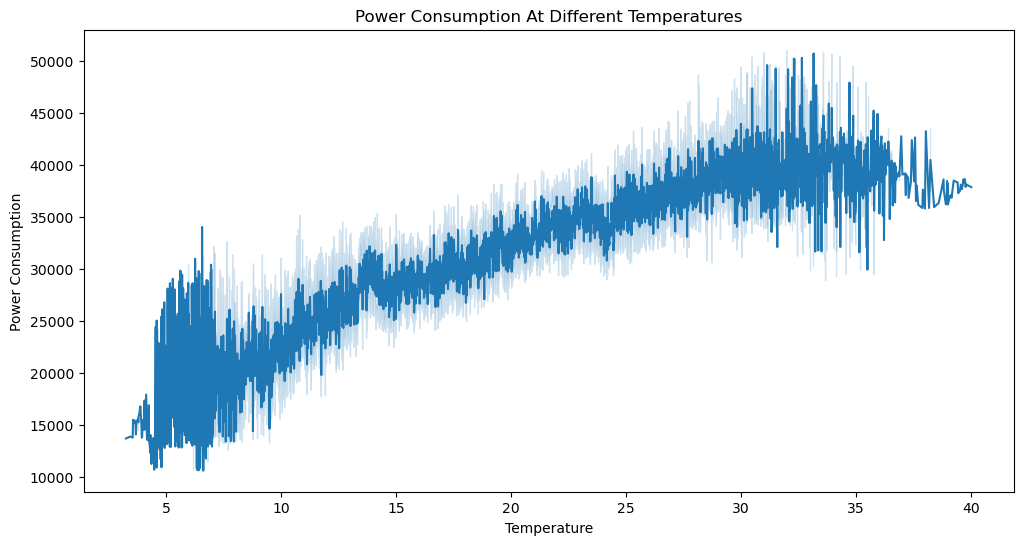

In [20]:
#Temperatures
plt.figure(figsize=(12, 6))
sns.lineplot(x='Temperature', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Temperature')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Temperatures')
plt.show()

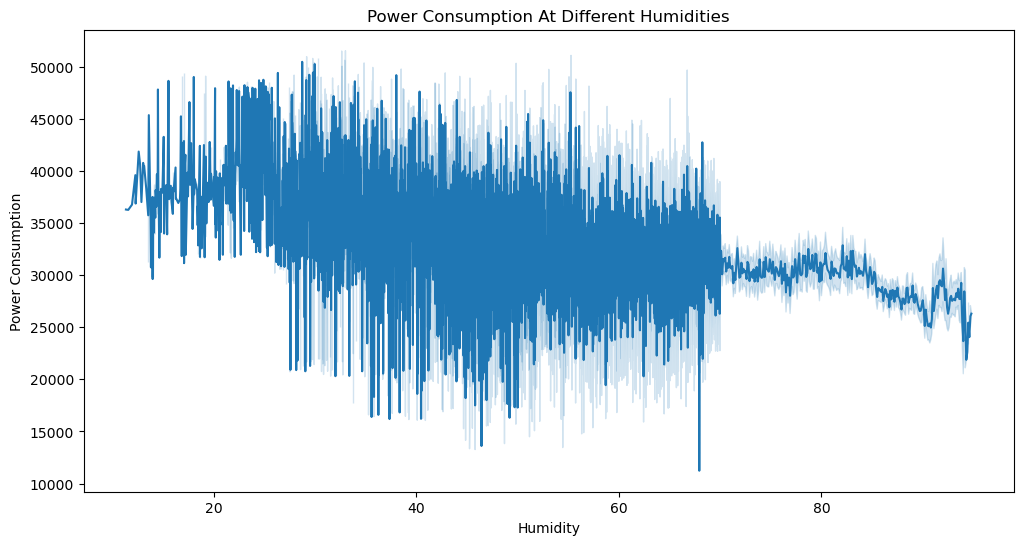

In [21]:
#Humdities
plt.figure(figsize=(12, 6))
sns.lineplot(x='Humidity', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Humidity')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Humidities')
plt.show()

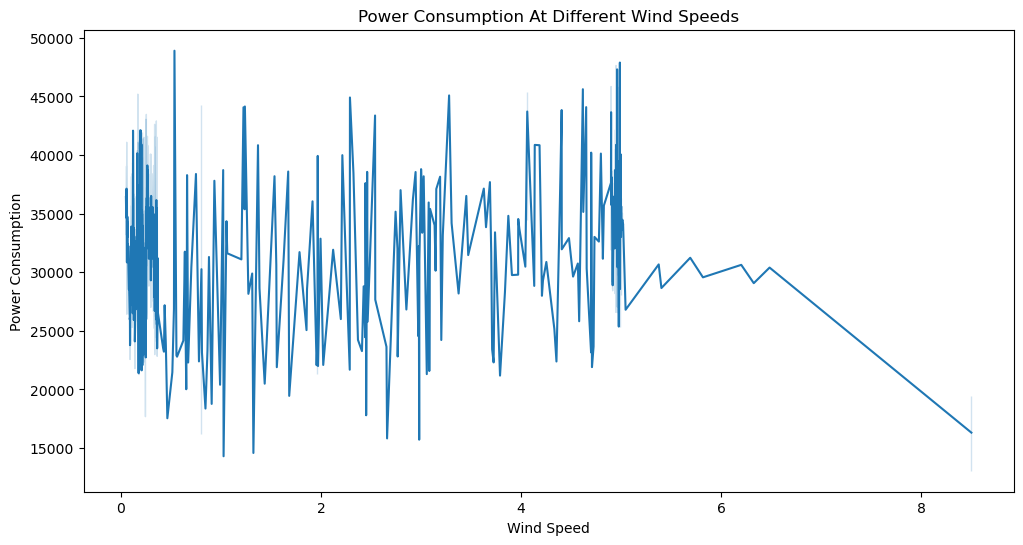

In [22]:
#Wind Speeds
plt.figure(figsize=(12, 6))
sns.lineplot(x='Wind Speed', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Wind Speed')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Wind Speeds')
plt.show()

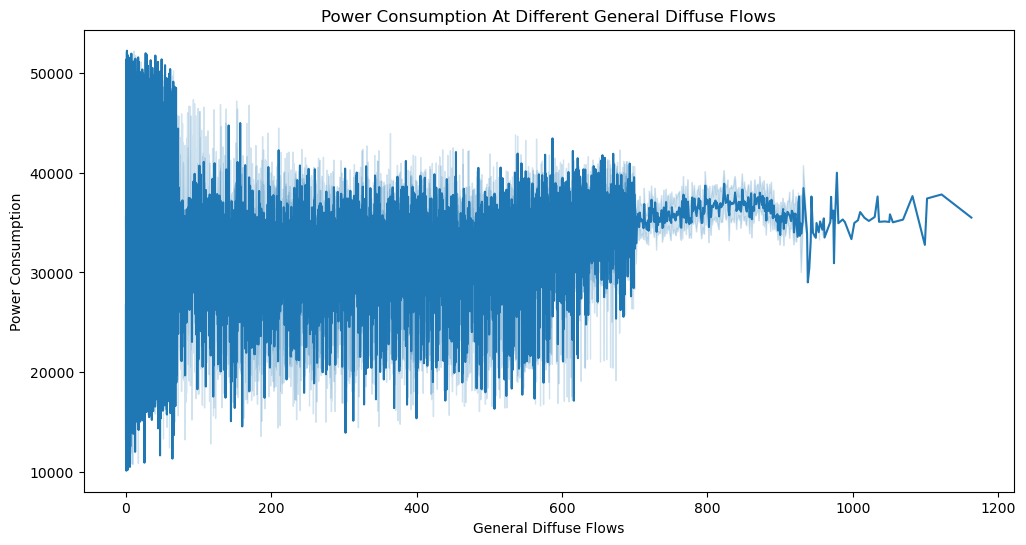

In [23]:
#General Diffuse Flows
plt.figure(figsize=(12, 6))
sns.lineplot(x='general diffuse flows', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('General Diffuse Flows')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different General Diffuse Flows')
plt.show()

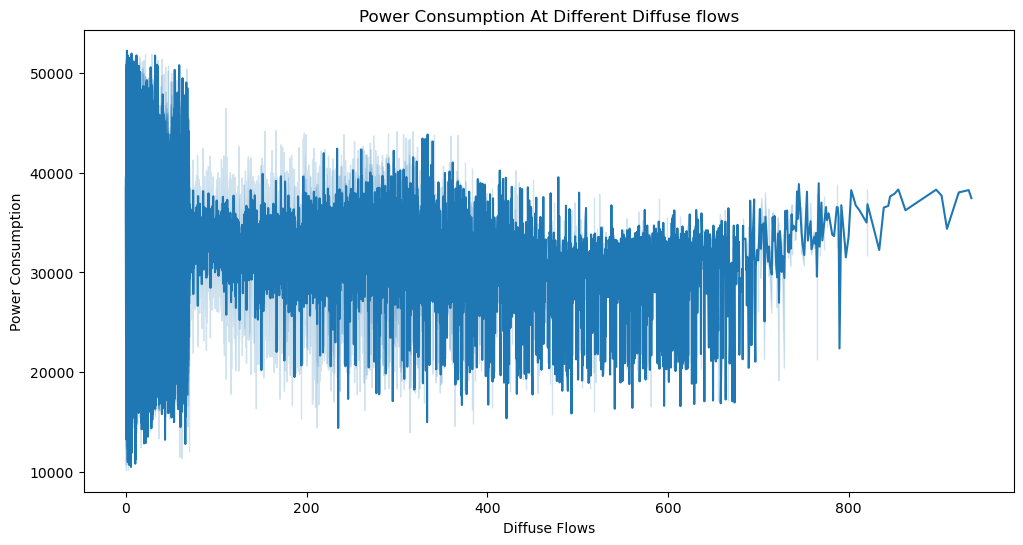

In [24]:
#Diffuse Flows
plt.figure(figsize=(12, 6))
sns.lineplot(x='diffuse flows', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Diffuse Flows')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Diffuse flows')
plt.show()

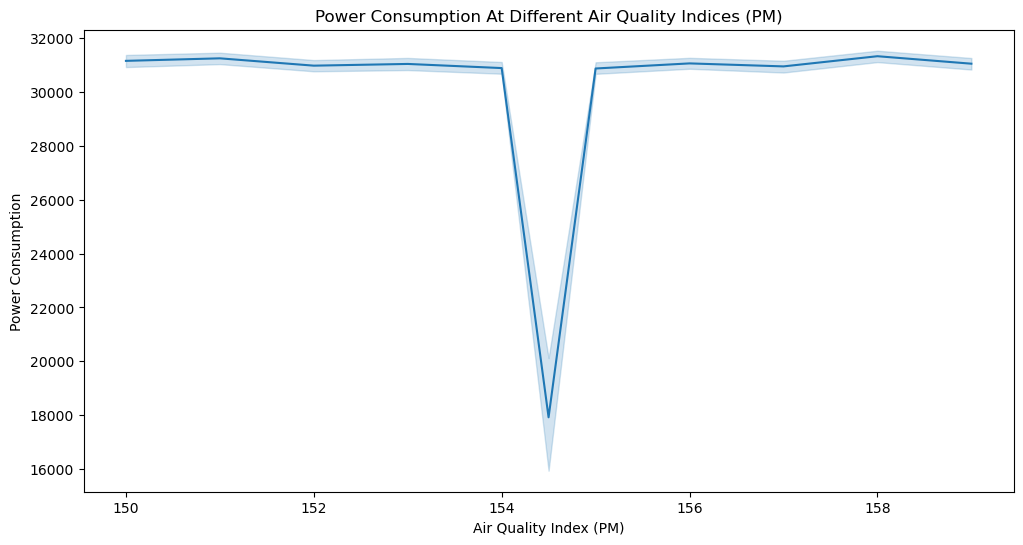

In [25]:
#Air Quality Index (PM)
plt.figure(figsize=(12, 6))
sns.lineplot(x='Air Quality Index (PM)', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Air Quality Index (PM)')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Air Quality Indices (PM)')
plt.show()

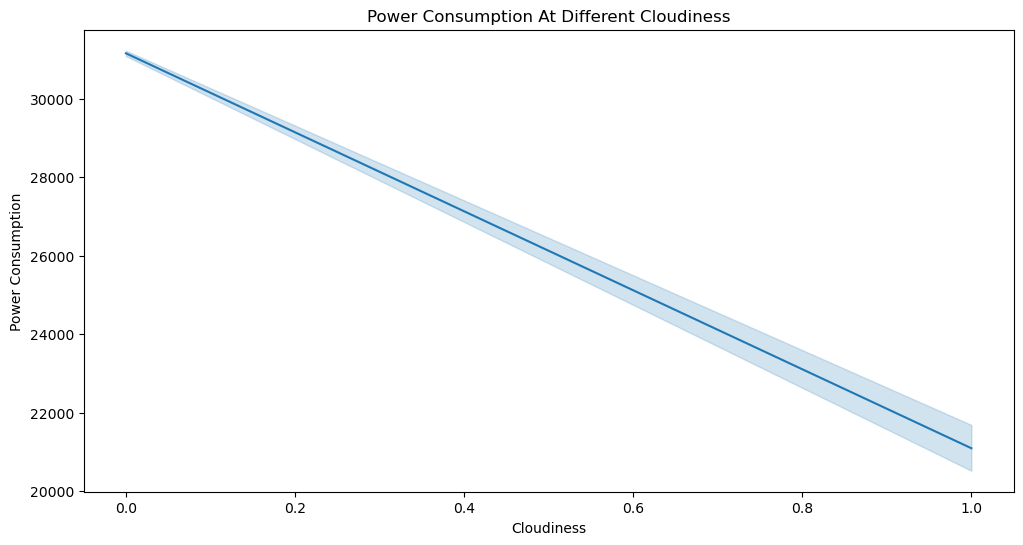

In [26]:
#Cloudiness
plt.figure(figsize=(12, 6))
sns.lineplot(x='Cloudiness', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Cloudiness')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Cloudiness')
plt.show()

<Axes: >

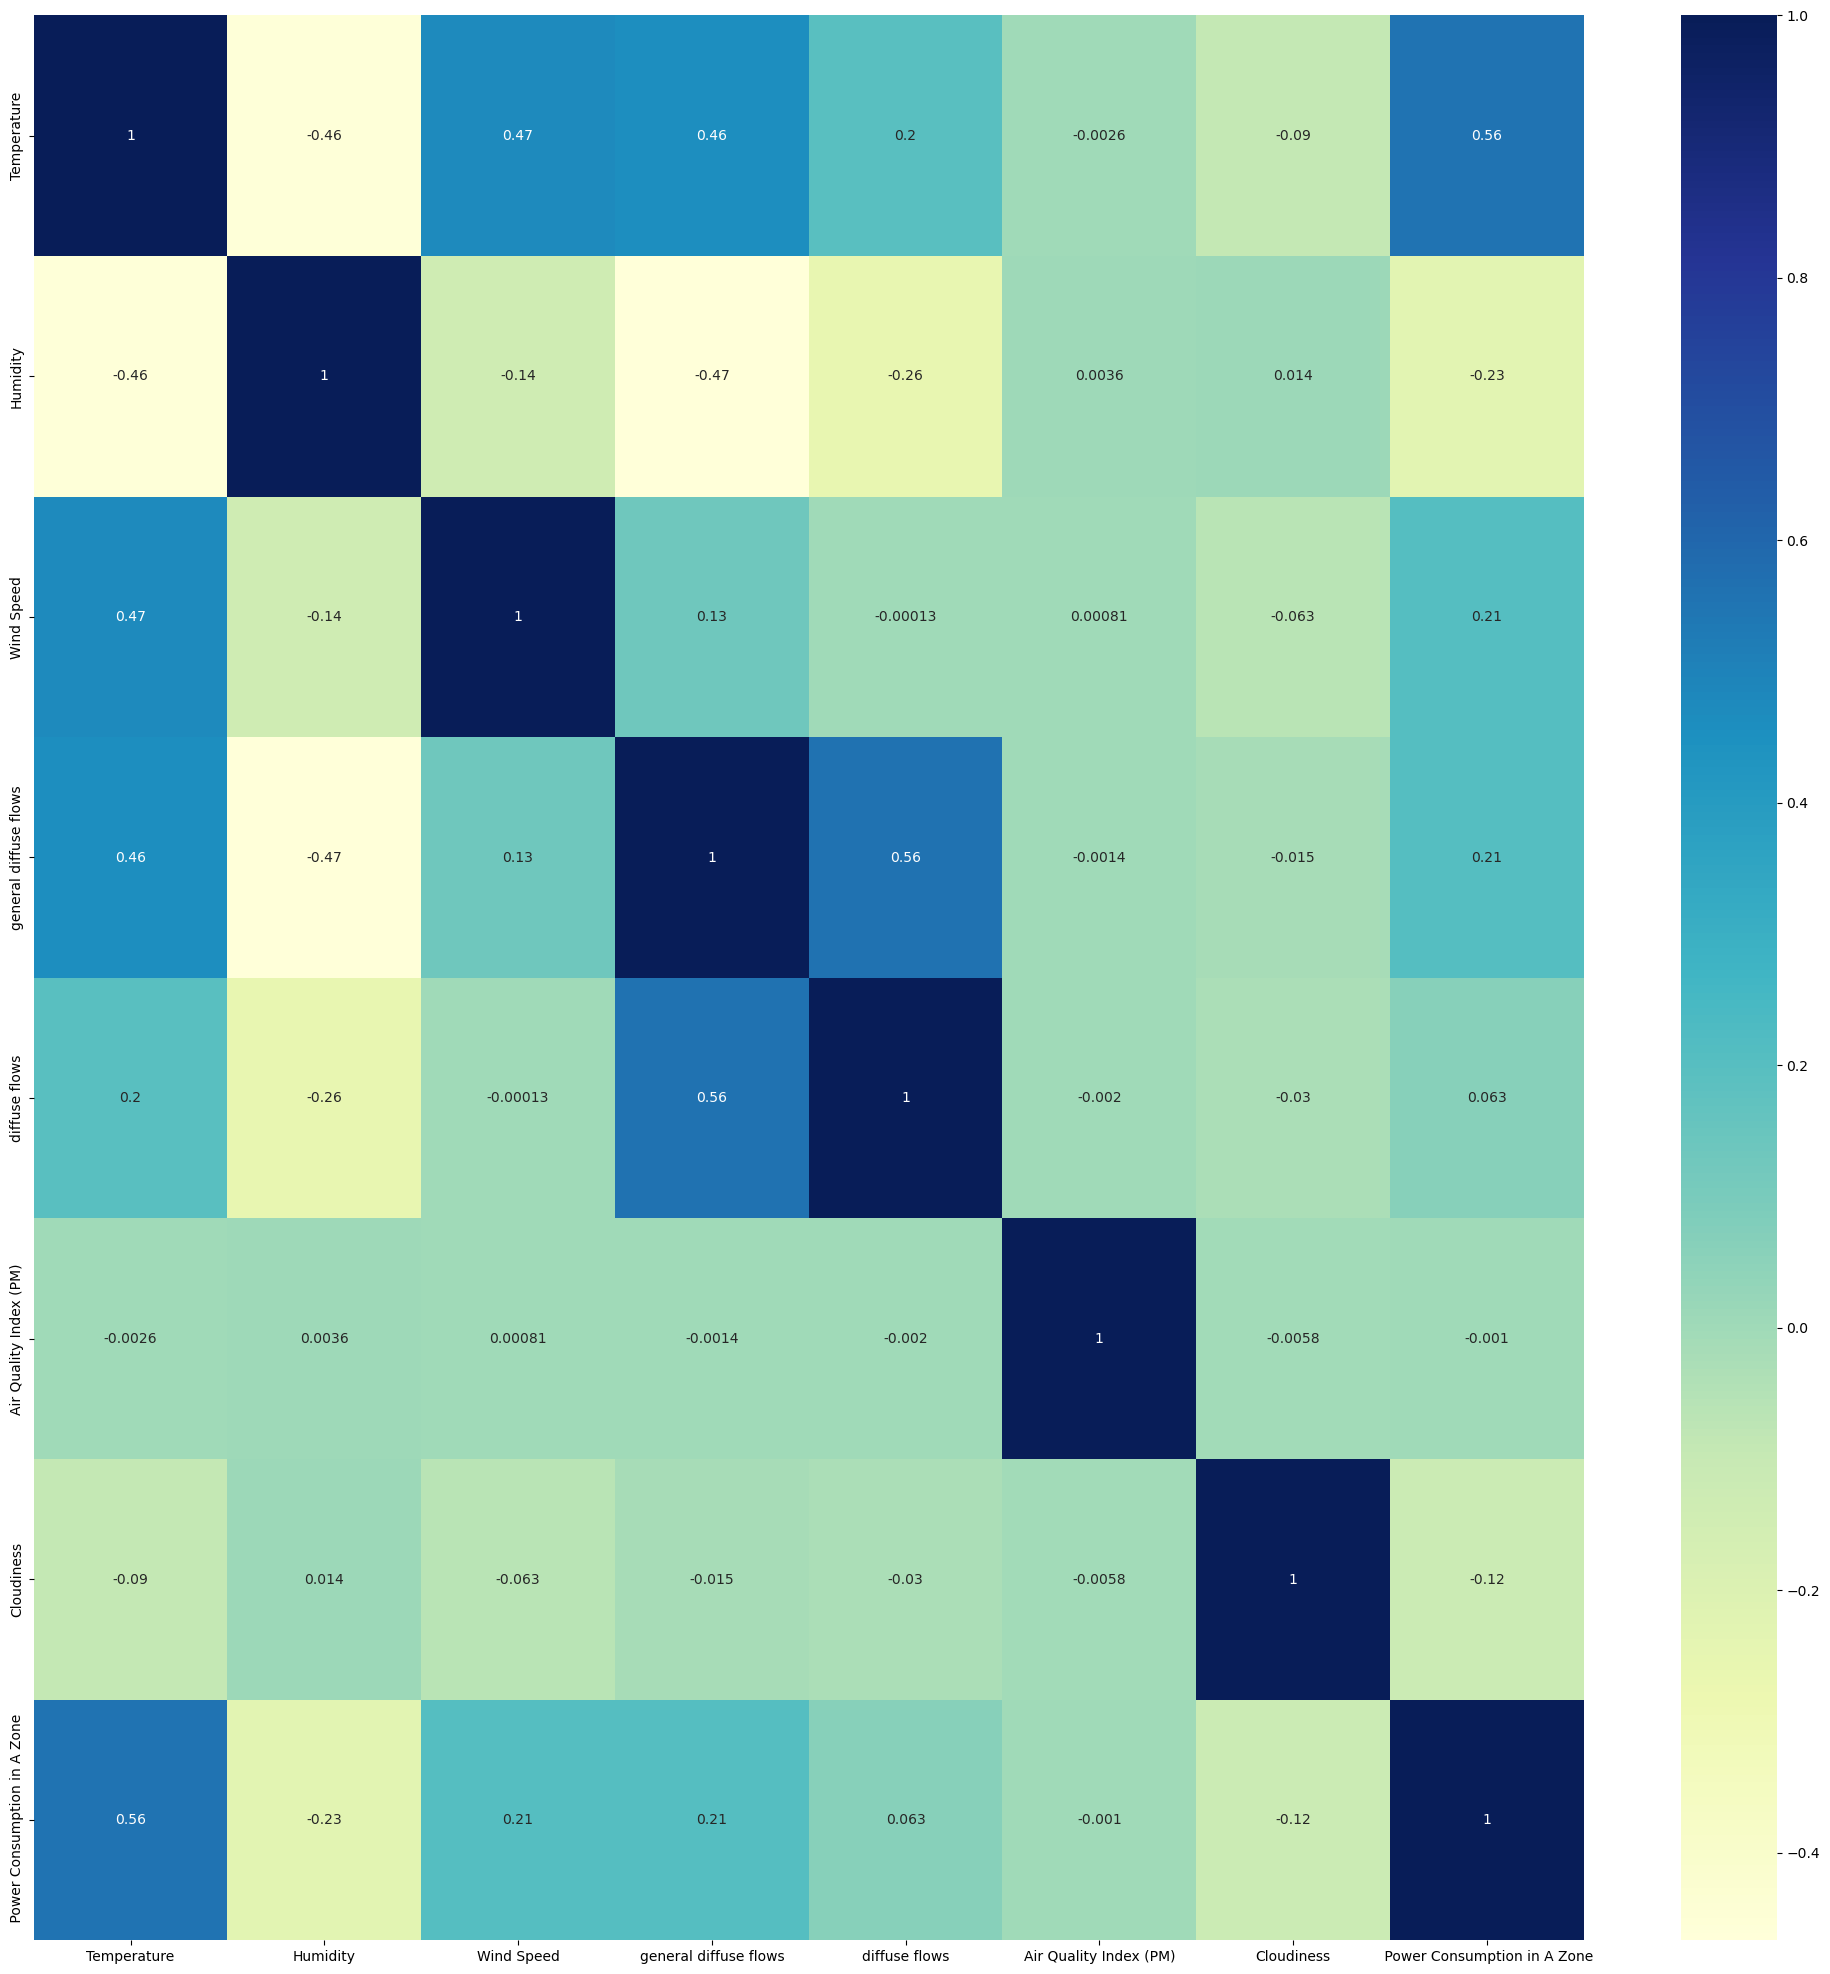

In [27]:
plt.figure(figsize=(25, 25))
co_mtx = df_con.corr(numeric_only=True)
sns.heatmap(co_mtx, cmap="YlGnBu", annot=True)

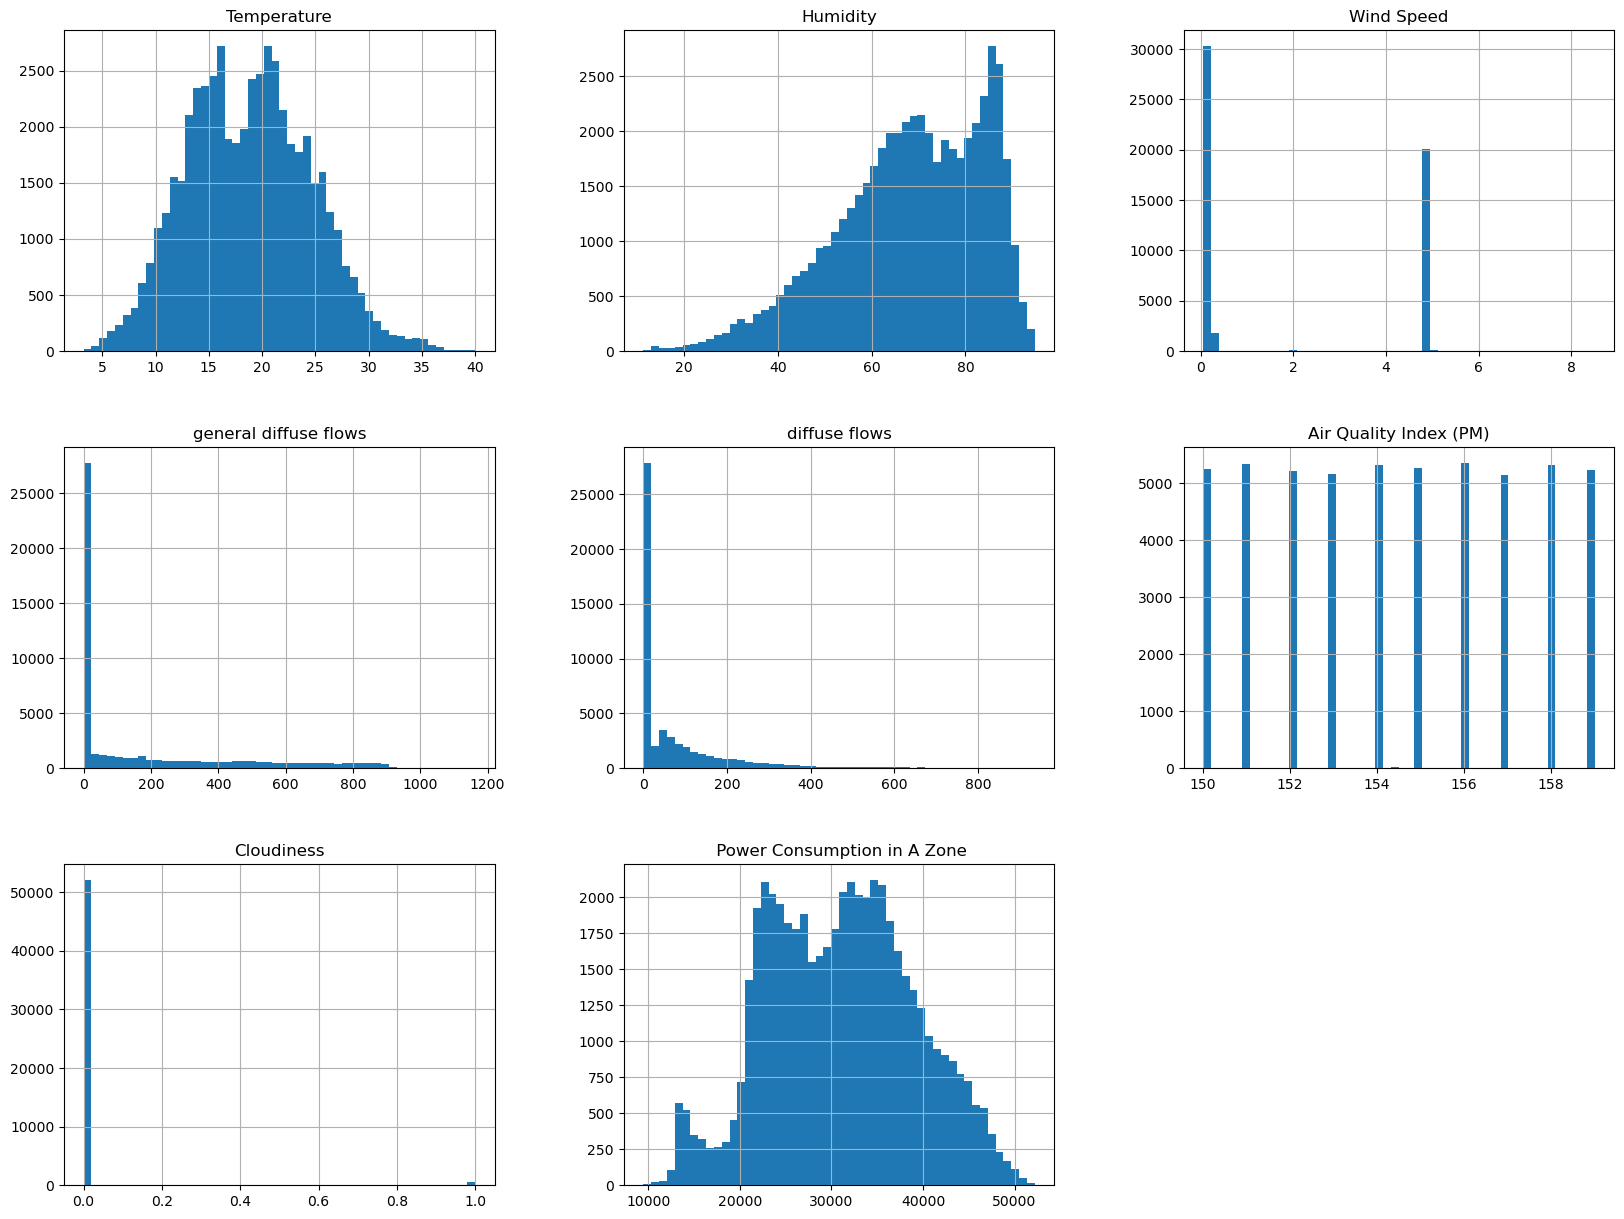

In [28]:
df_con.hist(bins=50,figsize=(20,15))
plt.show()

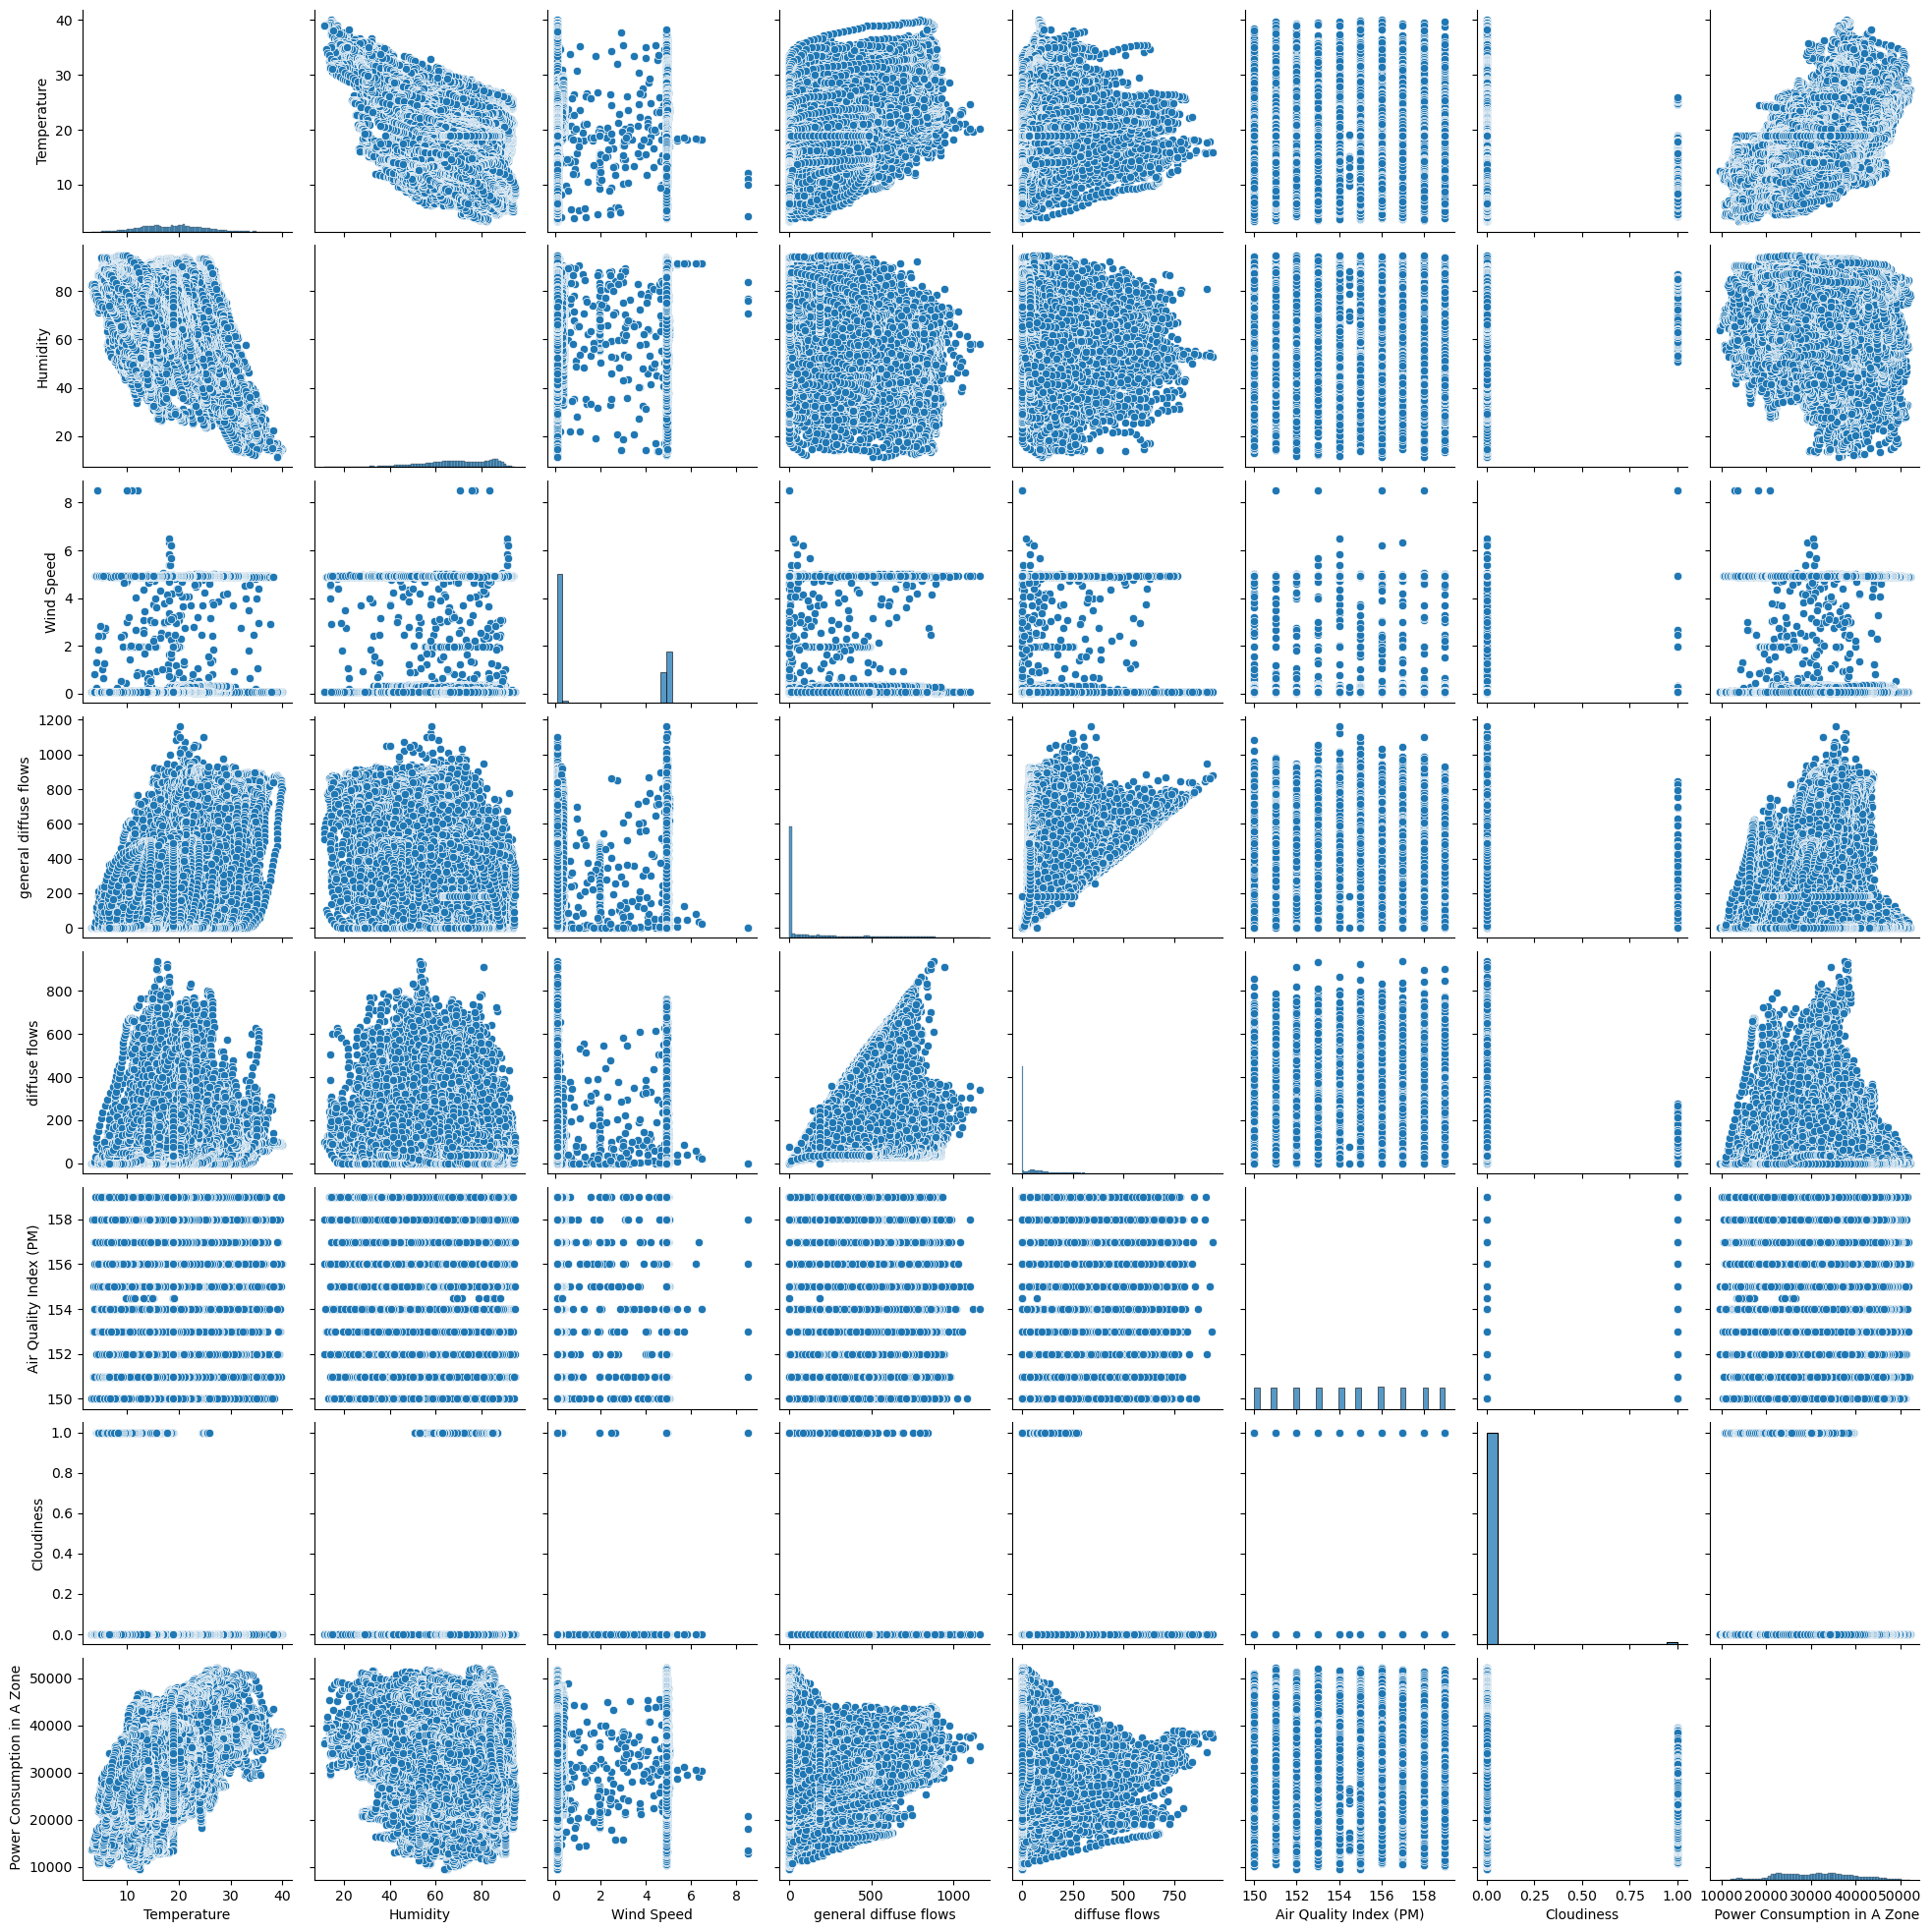

In [29]:
sns.pairplot(df_con[['Temperature', 'Humidity', 'Wind Speed', 'general diffuse flows', 'diffuse flows', 'Air Quality Index (PM)', 'Cloudiness',' Power Consumption in A Zone']])
plt.show()

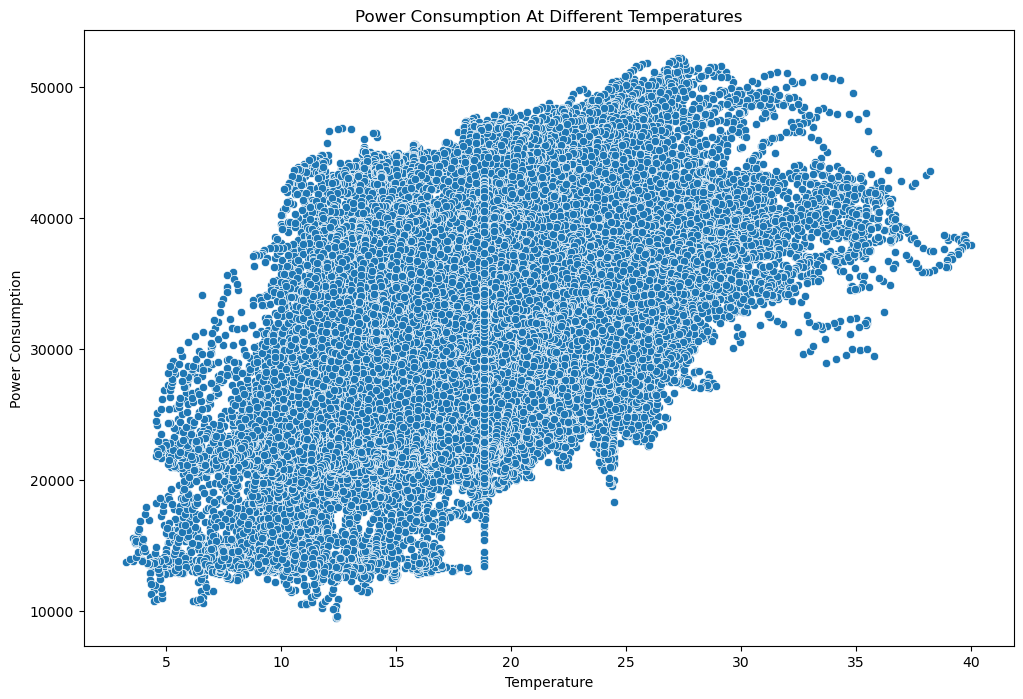

In [30]:
#Temperatures
plt.figure(figsize=(12, 8))
sns.scatterplot(x='Temperature', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Temperature')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Temperatures')
plt.show()

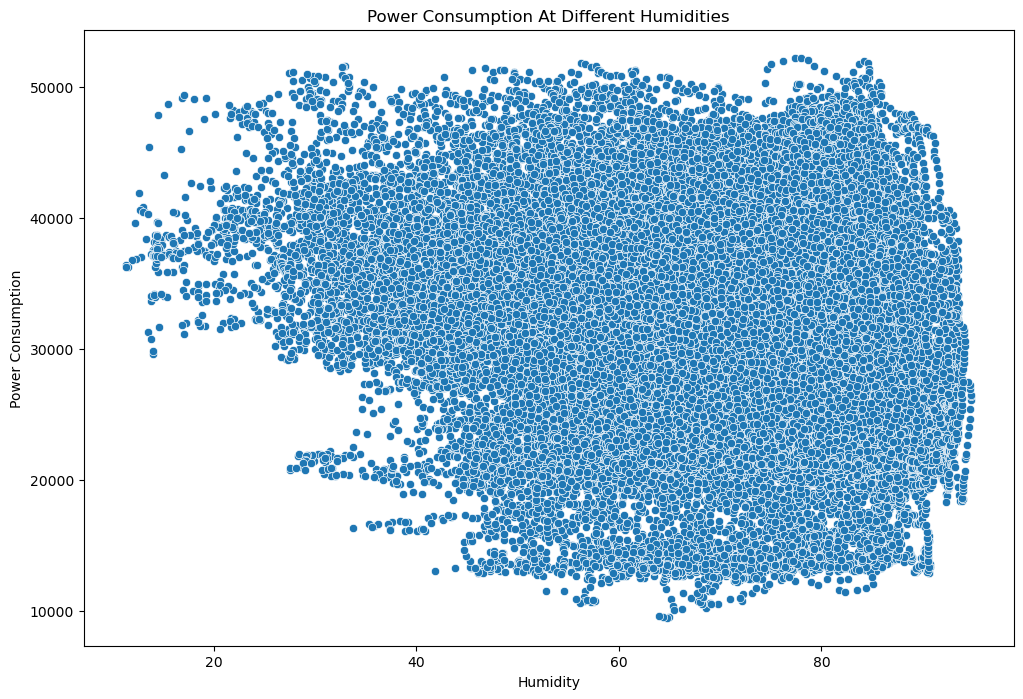

In [31]:
#Humdities
plt.figure(figsize=(12, 8))
sns.scatterplot(x='Humidity', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Humidity')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Humidities')
plt.show()

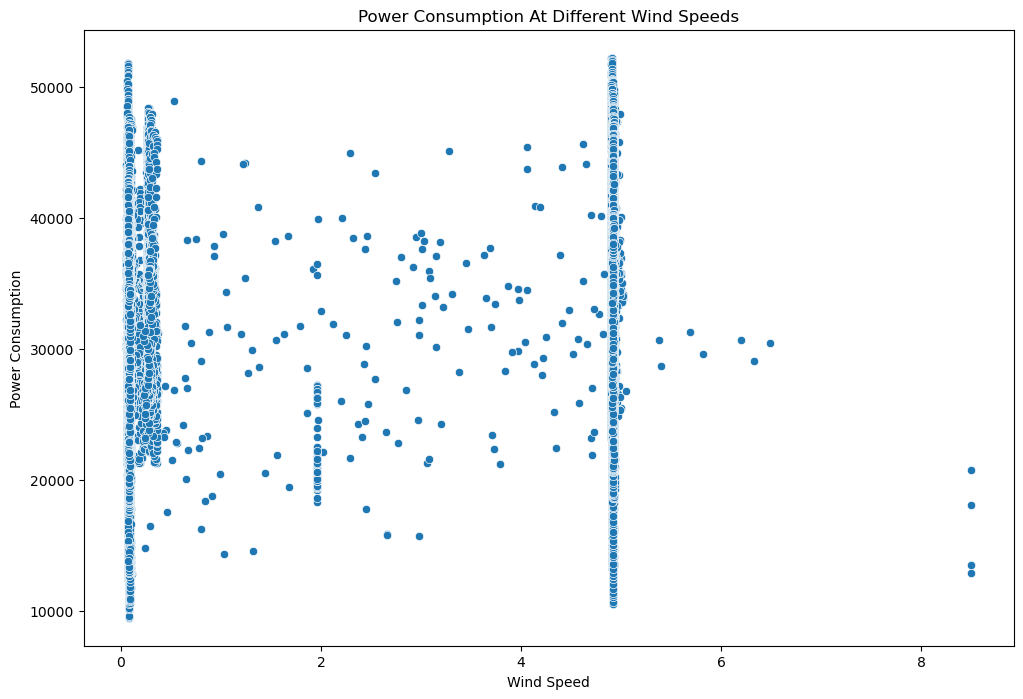

In [32]:
#Wind Speeds
plt.figure(figsize=(12, 8))
sns.scatterplot(x='Wind Speed', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Wind Speed')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Wind Speeds')
plt.show()

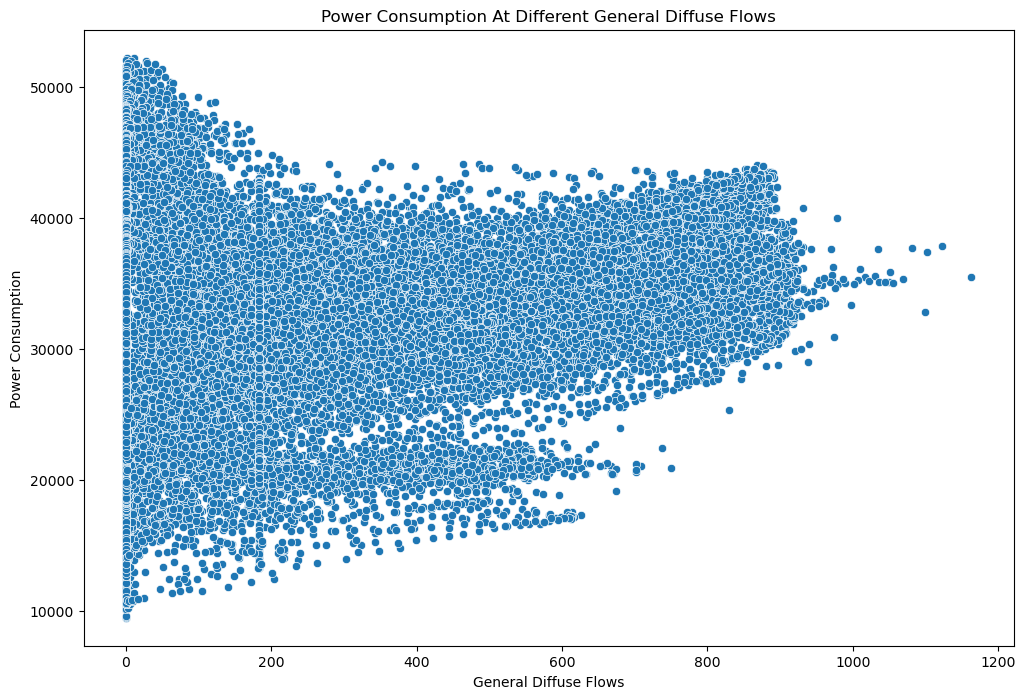

In [33]:
#General Diffuse Flows
plt.figure(figsize=(12, 8))
sns.scatterplot(x='general diffuse flows', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('General Diffuse Flows')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different General Diffuse Flows')
plt.show()

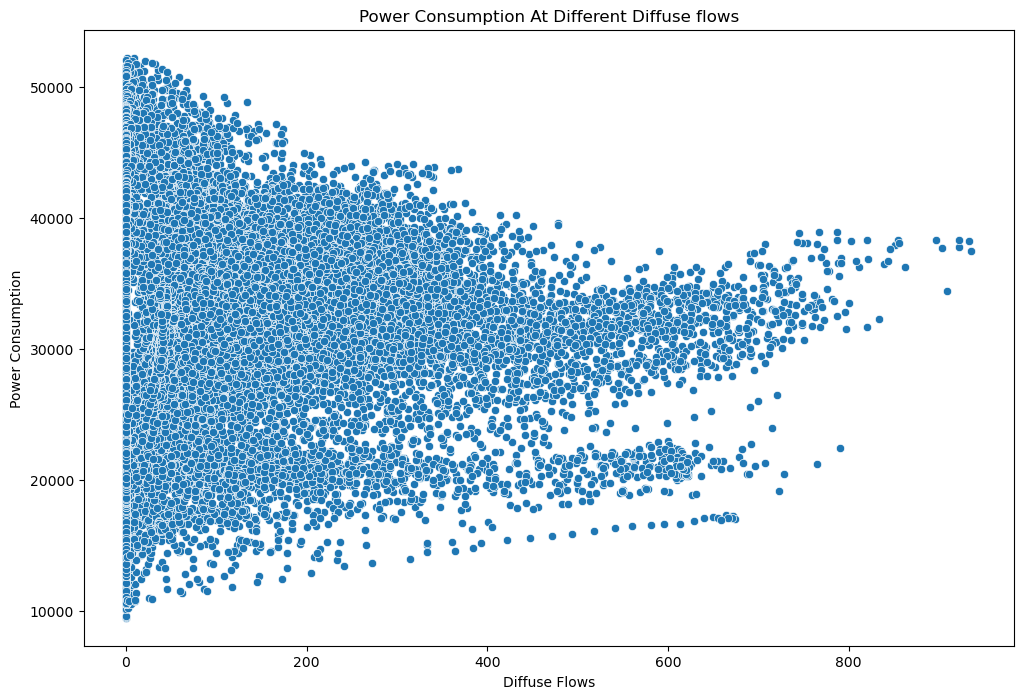

In [34]:
#Diffuse Flows
plt.figure(figsize=(12, 8))
sns.scatterplot(x='diffuse flows', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Diffuse Flows')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Diffuse flows')
plt.show()

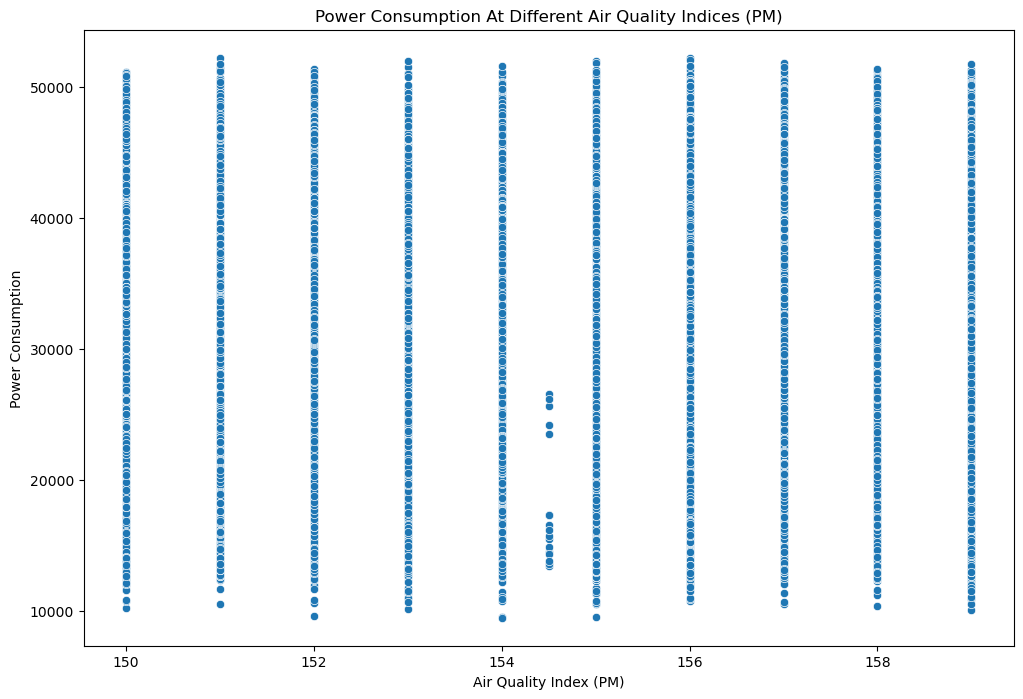

In [35]:
#Air Quality Index (PM)
plt.figure(figsize=(12, 8))
sns.scatterplot(x='Air Quality Index (PM)', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Air Quality Index (PM)')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Air Quality Indices (PM)')
plt.show()

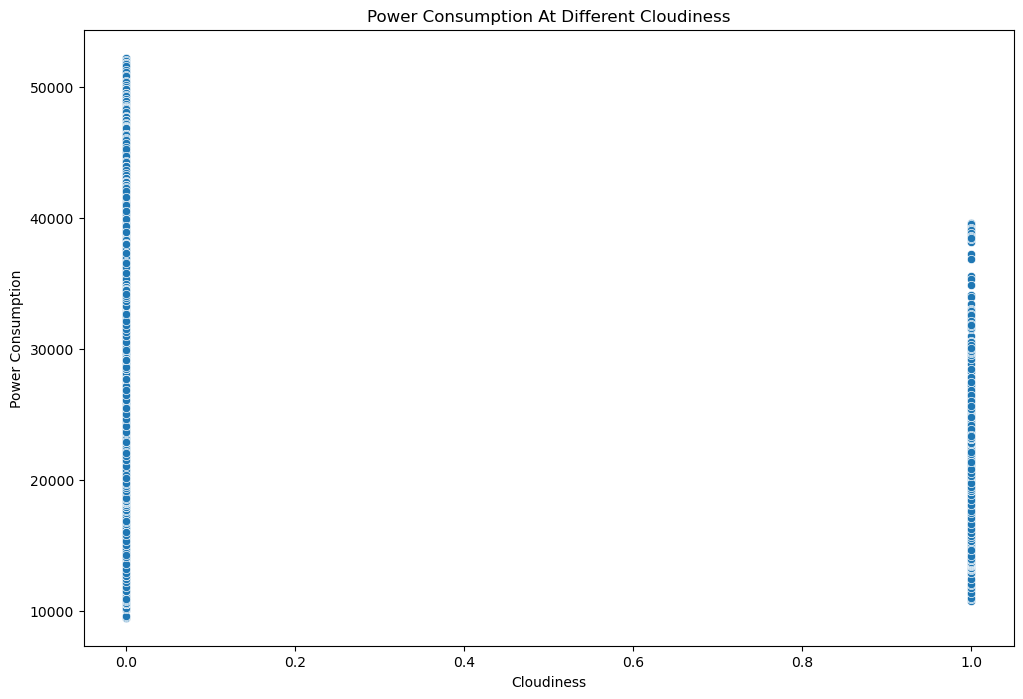

In [36]:
#Cloudiness
plt.figure(figsize=(12, 8))
sns.scatterplot(x='Cloudiness', y=' Power Consumption in A Zone', data=df_con)
plt.xlabel('Cloudiness')
plt.ylabel('Power Consumption')
plt.title('Power Consumption At Different Cloudiness')
plt.show()

In [37]:
from sklearn.preprocessing import RobustScaler
scale=RobustScaler()
df_conscaled=scale.fit_transform(df_con) 
df_conscaled=pd.DataFrame(df_conscaled)
df_conscaled.columns=df_con.columns
df_conscaled

,Temperature,Humidity,Wind Speed,general diffuse flows,diffuse flows,Air Quality Index (PM),Cloudiness,Power Consumption in A Zone
0,-1.457053,0.169991,-0.000620,-0.019411,-0.043198,0.6,1.0,0.239170
1,-1.474274,0.200347,-0.000620,-0.019351,-0.043537,0.8,1.0,-0.114757
2,-1.486269,0.200347,-0.001240,-0.019376,-0.043388,-0.8,1.0,-0.172055
3,-1.509072,0.222029,-0.000620,-0.019285,-0.043428,-0.8,1.0,-0.247100
4,-1.532825,0.252385,-0.001034,-0.019420,-0.043537,-0.2,1.0,-0.321637
...,...,...,...,...,...,...,...,...
52578,0.000000,0.248049,0.001654,1.356723,0.343942,0.4,0.0,0.271622
52579,0.000000,0.156982,0.000620,1.405313,0.331682,0.4,0.0,0.271115
52580,0.000000,0.009540,-0.000207,1.452010,0.329290,0.4,0.0,0.223958
52581,0.000000,-0.092368,0.000000,1.485455,0.328094,-0.6,0.0,0.233592


In [38]:
X=df_conscaled.drop([' Power Consumption in A Zone'] , axis=1)
Y=df_conscaled[' Power Consumption in A Zone']
Y=pd.DataFrame(Y)

In [39]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [40]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(42066, 7)
(10517, 7)
(42066, 1)
(10517, 1)


In [41]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error,root_mean_squared_error

In [42]:
from sklearn.linear_model import LinearRegression
lin=LinearRegression()
lin=lin.fit(x_train,y_train)
y_pred_lin=lin.predict(x_test)
r2_lin=r2_score(y_test, y_pred_lin)
mae_lin=mean_absolute_error(y_test, y_pred_lin)
mse_lin=mean_squared_error(y_test, y_pred_lin)
rmse_lin=root_mean_squared_error(y_test, y_pred_lin)
print('---------- LINEAR REGRESSION ----------')
print()
print('R2 Score :',r2_lin)
print('MAE Score :',mae_lin)
print('MSE Score :',mse_lin)
print('RMSE Score :',rmse_lin)

---------- LINEAR REGRESSION ----------

R2 Score : 0.33135472960161283
MAE Score : 0.44192822756906636
MSE Score : 0.3008258410482718
RMSE Score : 0.5484759256779388


In [43]:
from sklearn.tree import DecisionTreeRegressor
dtr=DecisionTreeRegressor(random_state=42)
dtr=dtr.fit(x_train, y_train)
y_pred_dtr=dtr.predict(x_test)
r2_dt=r2_score(y_test, y_pred_dtr)
mae_dt=mean_absolute_error(y_test, y_pred_dtr)
mse_dt=mean_squared_error(y_test, y_pred_dtr)
rmse_dt=root_mean_squared_error(y_test, y_pred_dtr)
print('---------- DECISION TREE REGRESSION ----------')
print()
print('R2 Score :',r2_dt)
print('MAE Score :',mae_dt)
print('MSE Score :',mse_dt)
print('RMSE Score :',rmse_dt)

---------- DECISION TREE REGRESSION ----------

R2 Score : 0.25537695644656644
MAE Score : 0.35303303114983575
MSE Score : 0.3350085063899764
RMSE Score : 0.5787991934945801


In [44]:
from sklearn.svm import SVR
svr=SVR(kernel='linear')
svr=svr.fit(x_train, y_train)
y_pred_svr=svr.predict(x_test)
r2_svr=r2_score(y_test, y_pred_svr)
mae_svr=mean_absolute_error(y_test, y_pred_svr)
mse_svr=mean_squared_error(y_test, y_pred_svr)
rmse_svr=root_mean_squared_error(y_test, y_pred_svr)
print('---------- SUPPORT VECTOR REGRESSION ----------')
print()
print('R2 Score :',r2_svr)
print('MAE Score :',mae_svr)
print('MSE Score :',mse_svr)
print('RMSE Score :',rmse_svr)

---------- SUPPORT VECTOR REGRESSION ----------

R2 Score : 0.3007101674029663
MAE Score : 0.43474362379070475
MSE Score : 0.3146129365458162
RMSE Score : 0.5609036784919637


In [45]:
from sklearn.ensemble import RandomForestRegressor
rfr=RandomForestRegressor(n_estimators=100, random_state=42)
rfr=rfr.fit(x_train, y_train)
y_pred_rfr=rfr.predict(x_test)
r2_rf=r2_score(y_test, y_pred_rfr)
mae_rf=mean_absolute_error(y_test, y_pred_rfr)
mse_rf=mean_squared_error(y_test, y_pred_rfr)
rmse_rf=root_mean_squared_error(y_test, y_pred_rfr)
print('---------- RANDOM FOREST REGRESSION ----------')
print()
print('R2 Score :',r2_rf)
print('MAE Score :',mae_rf)
print('MSE Score :',mse_rf)
print('RMSE Score :',rmse_rf)

---------- RANDOM FOREST REGRESSION ----------

R2 Score : 0.6370355404724979
MAE Score : 0.2822379161842305
MSE Score : 0.16329897726328949
RMSE Score : 0.4041026815838884


In [46]:
from sklearn.model_selection import KFold , cross_val_score 
n=15
kf=KFold(n_splits=n , shuffle=True , random_state=42)

In [47]:
cvscore_lin=cross_val_score(lin, X , Y , cv=kf)
print(cvscore_lin)
print('---------------------------------------------------------------------')
print('MEAN SCORE FOR LINEAR REGRESSION : ',cvscore_lin.mean())

[0.33266642 0.32742163 0.33392466 0.32896631 0.34075361 0.3336442
 0.31226122 0.33418797 0.32369952 0.30681243 0.32129644 0.33221098
 0.32358406 0.31891411 0.32699646]
---------------------------------------------------------------------
MEAN SCORE FOR LINEAR REGRESSION :  0.3264893343014695


In [48]:
cvscore_dtr=cross_val_score(dtr, X , Y , cv=kf)
print(cvscore_dtr)
print('---------------------------------------------------------------------')
print('MEAN SCORE FOR DECISION TREE REGRESSION : ',cvscore_dtr.mean())

[0.35296328 0.25864369 0.2969642  0.30454572 0.28471563 0.34271749
 0.29709726 0.29742474 0.2435399  0.27288776 0.24476018 0.30951615
 0.27142075 0.28587358 0.30923975]
---------------------------------------------------------------------
MEAN SCORE FOR DECISION TREE REGRESSION :  0.29148733924808534


In [49]:
cvscore_svr=cross_val_score(svr, X , Y , cv=kf)
print(cvscore_svr)
print('---------------------------------------------------------------------')
print('MEAN SCORE FOR SUPPORT VECTOR REGRESSION : ',cvscore_svr.mean())

[0.29705711 0.30142979 0.30398626 0.29911539 0.31501156 0.30589451
 0.27990221 0.303422   0.29273221 0.26731134 0.29196383 0.29445708
 0.30240546 0.2878408  0.31140588]
---------------------------------------------------------------------
MEAN SCORE FOR SUPPORT VECTOR REGRESSION :  0.29692902867992


In [50]:
cvscore_rfr=cross_val_score(rfr, X , Y , cv=kf)
print(cvscore_rfr)
print('---------------------------------------------------------------------')
print('MEAN SCORE FOR SUPPORT VECTOR REGRESSION : ',cvscore_rfr.mean())

[0.66890435 0.62987832 0.63370456 0.65630469 0.64037029 0.66533037
 0.64715837 0.64400228 0.63290737 0.62348133 0.6268187  0.64164327
 0.63130564 0.64957144 0.62960823]
---------------------------------------------------------------------
MEAN SCORE FOR SUPPORT VECTOR REGRESSION :  0.6413992813060564
